Dataset Link: https://www.kaggle.com/datasets/joniarroba/noshowappointments

Testing Availability

In [1]:
import torch
import torch.nn as nn
import time
import numpy as np
import matplotlib.pyplot as plt

# Check PyTorch and GPU
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
CUDA available: True
Selected device: cuda
GPU: Tesla T4


XOR using pytorch

In [2]:
X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])

model = nn.Sequential(
    nn.Linear(2, 3), nn.Sigmoid(),
    nn.Linear(3, 1), nn.Sigmoid()
)

loss_fn = nn.BCELoss()
optimiser = torch.optim.Adam(model.parameters(), lr=0.05)

print(model)

Sequential(
  (0): Linear(in_features=2, out_features=3, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=3, out_features=1, bias=True)
  (3): Sigmoid()
)


Training the XOR network

In [3]:
model = model.to(device)
X = X.to(device)
y = y.to(device)

optimiser = torch.optim.Adam(model.parameters(), lr=0.05)

loss_history = []

for epoch in range(2000):
    optimiser.zero_grad()       # Clears previous gradients

    prediction = model(X)       # Forward pass
    loss = loss_fn(prediction, y)

    loss.backward()             # Calculate gradients automatically
    optimiser.step()            # Update weights

    loss_history.append(loss.item())

    if epoch % 400 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.6f}")

Epoch 0: Loss = 0.696683
Epoch 400: Loss = 0.007391
Epoch 800: Loss = 0.002421
Epoch 1200: Loss = 0.001231
Epoch 1600: Loss = 0.000744


In [4]:
with torch.no_grad():
    predictions = model(X)

print("Predictions:")
print(predictions.cpu().numpy().round(4))

print("\nRounded predictions:")
print((predictions >= 0.5).int().cpu().numpy())

print("\nActual values:")
print(y.cpu().numpy())

Predictions:
[[0.000e+00]
 [9.995e-01]
 [9.995e-01]
 [9.000e-04]]

Rounded predictions:
[[0]
 [1]
 [1]
 [0]]

Actual values:
[[0.]
 [1.]
 [1.]
 [0.]]


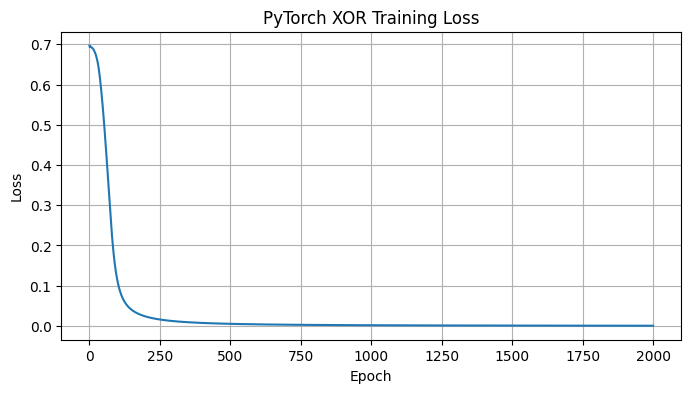

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PyTorch XOR Training Loss")
plt.grid(True)
plt.show()

What does loss.backward() replace?

In Assignment 01, we manually calculated gradients for every weight and bias using backpropagation. In PyTorch, loss.backward() uses automatic differentiation (autograd) to calculate these gradients automatically.

In [6]:
import pandas as pd

df = pd.read_csv("KaggleV2-May-2016.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["No-show"].value_counts())

Dataset shape: (110527, 14)

Columns:
['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay', 'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show']

Target distribution:
No-show
No     88208
Yes    22319
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#Select features used in Week 1
features = [
    "Age", "Gender", "Scholarship",
    "Hipertension", "Diabetes", "Alcoholism",
    "Handcap", "SMS_received"
]

X_health = df[features].copy()

#Convert Gender into numeric columns
X_health = pd.get_dummies(
    X_health,
    columns=["Gender"],
    drop_first=True,
    dtype=int
)

# Convert target: No = 0, Yes = 1
y_health = (df["No-show"] == "Yes").astype(int)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_health, y_health,
    test_size=0.2,
    random_state=42,
    stratify=y_health
)

# Scale features using training data only
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))
print("\nNo-show rate in training:", round(y_train.mean() * 100, 2), "%")

Training features: (88421, 8)
Testing features: (22106, 8)
Training samples: 88421
Testing samples: 22106

No-show rate in training: 20.19 %


In [8]:
# Converts NumPy arrays to PyTorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

y_test_t = torch.tensor(
    y_test.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

# Defining neural network
class HealthcareNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)

health_model = HealthcareNN(X_train.shape[1]).to(device)

loss_fn_health = nn.BCEWithLogitsLoss()

optimiser_health = torch.optim.Adam(
    health_model.parameters(), lr=0.001
)

print(health_model)
print("Model device:", next(health_model.parameters()).device)

HealthcareNN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Linear(in_features=16, out_features=1, bias=True)
  )
)
Model device: cuda:0


epoch testing

In [9]:
# Move training and testing data to GPU
X_train_t = X_train_t.to(device)
X_test_t = X_test_t.to(device)
y_train_t = y_train_t.to(device)
y_test_t = y_test_t.to(device)

loss_history_health = []

for epoch in range(15):
    health_model.train()

    optimiser_health.zero_grad()

    outputs = health_model(X_train_t)
    loss = loss_fn_health(outputs, y_train_t)

    loss.backward()
    optimiser_health.step()

    loss_history_health.append(loss.item())

    print(f"Epoch {epoch + 1}/15 - Loss: {loss.item():.4f}")

Epoch 1/15 - Loss: 0.6221
Epoch 2/15 - Loss: 0.6199
Epoch 3/15 - Loss: 0.6177
Epoch 4/15 - Loss: 0.6155
Epoch 5/15 - Loss: 0.6133
Epoch 6/15 - Loss: 0.6111
Epoch 7/15 - Loss: 0.6088
Epoch 8/15 - Loss: 0.6065
Epoch 9/15 - Loss: 0.6043
Epoch 10/15 - Loss: 0.6021
Epoch 11/15 - Loss: 0.5999
Epoch 12/15 - Loss: 0.5976
Epoch 13/15 - Loss: 0.5954
Epoch 14/15 - Loss: 0.5932
Epoch 15/15 - Loss: 0.5909


Evaluation after training epochs

In [10]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

health_model.eval()

with torch.no_grad():
    logits = health_model(X_test_t)
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= 0.5).int()

y_true = y_test_t.cpu().numpy()
y_pred = predictions.cpu().numpy()

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Accuracy: 0.7981
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Confusion Matrix:
[[17642     0]
 [ 4464     0]]


In [12]:
for threshold in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred = (probabilities >= threshold).int().cpu().numpy()

    print(
        f"Threshold: {threshold} | "
        f"Accuracy: {accuracy_score(y_true, pred):.4f} | "
        f"Precision: {precision_score(y_true, pred, zero_division=0):.4f} | "
        f"Recall: {recall_score(y_true, pred, zero_division=0):.4f} | "
        f"F1: {f1_score(y_true, pred, zero_division=0):.4f}"
    )

Threshold: 0.5 | Accuracy: 0.7981 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000
Threshold: 0.4 | Accuracy: 0.4043 | Precision: 0.2093 | Recall: 0.7023 | F1: 0.3225
Threshold: 0.3 | Accuracy: 0.2094 | Precision: 0.2019 | Recall: 0.9868 | F1: 0.3352
Threshold: 0.2 | Accuracy: 0.2019 | Precision: 0.2019 | Recall: 1.0000 | F1: 0.3360
Threshold: 0.1 | Accuracy: 0.2019 | Precision: 0.2019 | Recall: 1.0000 | F1: 0.3360


Conclusion: Lowering the threshold increases recall but significantly reduces accuracy. The model struggles with the imbalanced dataset and does not outperform the Week 1 baseline meaningfully.

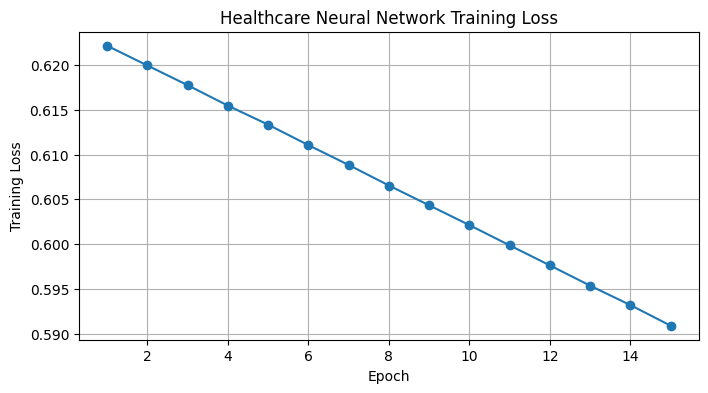

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, 16), loss_history_health, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Healthcare Neural Network Training Loss")
plt.grid(True)
plt.show()

CPU vs GPU timing comparison

In [14]:
import copy

def measure_one_epoch(target_device):
    model_copy = copy.deepcopy(health_model).to(target_device)
    model_copy.train()

    X_device = X_train_t.to(target_device)
    y_device = y_train_t.to(target_device)

    optimizer = torch.optim.Adam(model_copy.parameters(), lr=0.001)
    criterion = nn.BCEWithLogitsLoss()

    # Warm-up GPU
    if target_device.type == "cuda":
        for _ in range(2):
            optimizer.zero_grad()
            loss = criterion(model_copy(X_device), y_device)
            loss.backward()
            optimizer.step()
        torch.cuda.synchronize()

    start = time.time()

    optimizer.zero_grad()
    output = model_copy(X_device)
    loss = criterion(output, y_device)
    loss.backward()
    optimizer.step()

    if target_device.type == "cuda":
        torch.cuda.synchronize()

    return time.time() - start


cpu_time = measure_one_epoch(torch.device("cpu"))
gpu_time = measure_one_epoch(torch.device("cuda"))

print(f"CPU one-epoch time: {cpu_time:.4f} seconds")
print(f"GPU one-epoch time: {gpu_time:.4f} seconds")

CPU one-epoch time: 0.1747 seconds
GPU one-epoch time: 0.0022 seconds


Final Observations
- XOR predictions: all four correct.
- Healthcare test accuracy: 79.81%.
- Healthcare recall at threshold 0.5: 0%.
- Week 1 Logistic Regression accuracy: 79.93%, recall: 0%.
- CPU time: 0.1747 seconds; GPU time: 0.0022 seconds.
- The model struggled to identify the minority no-show class.